# Mini-projet — Prédire si un data center est de type *hyperscale*
**Module :** Technologies IA — TP1 Apprentissage supervisé · ENSA Fès · ILIA2
**Binôme :** Ben Abbou Ahlame N°:6 et **Barbara Kawtar N°:5

**Jeu de données :** data centers du monde entier extraits d'OpenStreetMap (`data_centers.csv`, 4 802 installations, 32 colonnes).

**Problème (classification binaire) :** à partir de la taille du bâtiment, de la localisation et de la qualité des métadonnées OSM, peut-on prédire si une installation est un data center **hyperscale** (grands opérateurs cloud) ou non ?

**Workflow :** chargement → exploration → nettoyage → features → split → modèles → validation croisée → réglage → évaluation finale → conclusion critique.

Le dataset parle des data centers (centres de données) dans le monde.

Chaque ligne est un data center, avec son type (hyperscale, colocation, télécom…), son pays, sa position GPS et la surface de son bâtiment. Il y en a 4 802, tirés d’OpenStreetMap.

Les deux autres fichiers sont des résumés par pays : l’un compte les data centers dans OSM, l’autre donne les chiffres officiels pour comparer.

## 1. Chargement des données


In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, zipfile, warnings
warnings.filterwarnings('ignore')

zipfile.ZipFile('archive.zip').extractall('data')

df = pd.read_csv('data/data_centers.csv')
print(df.shape)
df.head()

(4802, 32)


,osm_type,osm_id,name,name_en,operator,operator_short,operator_wikidata,owner,brand,facility_kind,...,longitude,footprint_area_m2,building_levels,height_m,start_date,website,wikidata,wikipedia,osm_last_edited,osm_url
0,way,950023771,ISPPro.al,NaN,NaN,NaN,NaN,NaN,NaN,unclassified,...,19.561237,110.0,NaN,NaN,NaN,NaN,NaN,NaN,2021-06-03,https://www.openstreetmap.org/way/950023771
1,way,765126865,NaN,NaN,NaN,NaN,NaN,NaN,NaN,unclassified,...,13.441489,69.0,NaN,NaN,NaN,NaN,NaN,NaN,2020-01-20,https://www.openstreetmap.org/way/765126865
2,node,7034711942,Centro de Datos Modular REFSA Telecomunicaciones,NaN,NaN,NaN,NaN,NaN,NaN,telecom_carrier,...,-58.207081,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-02-08,https://www.openstreetmap.org/node/7034711942
3,node,7034737759,Centro de Datos UPSTI,NaN,NaN,NaN,NaN,NaN,NaN,unclassified,...,-58.164591,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019-12-05,https://www.openstreetmap.org/node/7034737759
4,way,867314871,Claro,NaN,NaN,NaN,NaN,NaN,NaN,unclassified,...,-64.519637,26.0,NaN,NaN,NaN,NaN,NaN,NaN,2025-05-03,https://www.openstreetmap.org/way/867314871


In [ ]:
df.info()
print(df.isnull().mean().round(2).sort_values(ascending=False).head(15))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4802 entries, 0 to 4801
Data columns (total 32 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   osm_type           4802 non-null   object 
 1   osm_id             4802 non-null   int64  
 2   name               3669 non-null   object 
 3   name_en            82 non-null     object 
 4   operator           2888 non-null   object 
 5   operator_short     360 non-null    object 
 6   operator_wikidata  1508 non-null   object 
 7   owner              141 non-null    object 
 8   brand              28 non-null     object 
 9   facility_kind      4802 non-null   object 
 10  tagging_scheme     4802 non-null   object 
 11  country            4800 non-null   object 
 12  country_iso2       4800 non-null   object 
 13  country_iso3       4799 non-null   object 
 14  continent          4800 non-null   object 
 15  subregion          4800 non-null   object 
 16  country_match      4800 

## 2. Exploration
La colonne `facility_kind` décrit le type d'installation. La valeur `unclassified` signifie **« type inconnu »**, pas « autre type » : on ne peut pas dire que ces lignes ne sont pas hyperscale.

facility_kind
unclassified            3226
colocation               723
hyperscale               604
telecom_carrier          160
research_or_academic      42
financial                 38
government_or_public       9
Name: count, dtype: int64


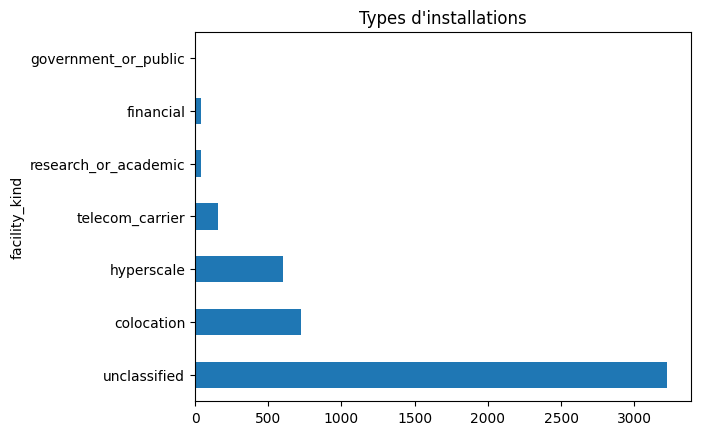

In [ ]:
print(df['facility_kind'].value_counts())
df['facility_kind'].value_counts().plot(kind='barh', title='Types d\'installations'); plt.show()

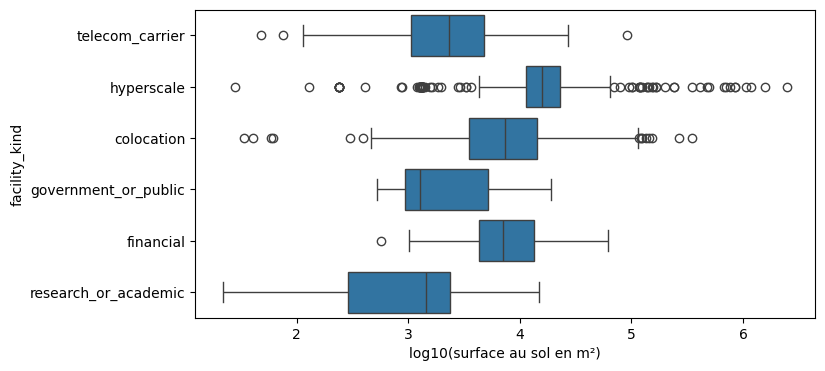

continent
Africa                       80
Asia                        629
Europe                     1813
North America              1926
Oceania                     179
Seven seas (open ocean)       1
South America               172
dtype: int64


In [ ]:
# Taille du bâtiment par type (échelle log)
lab = df[df.facility_kind != 'unclassified']
plt.figure(figsize=(8,4))
sns.boxplot(data=lab, y='facility_kind', x=np.log10(lab['footprint_area_m2']))
plt.xlabel('log10(surface au sol en m²)'); plt.show()
print(df.groupby('continent').size())

## 3. Définition de la cible et choix des variables

**Cible :** `is_hyperscale = 1` si `facility_kind == 'hyperscale'`, sinon 0.
On **retire les lignes `unclassified`** (type inconnu) : les garder comme « non-hyperscale » fausserait la cible.

**Fuite de données (data leakage) :** `facility_kind` est très probablement déduit du nom / de l'opérateur (ex. AWS, Google, Microsoft). On **exclut donc** `name`, `operator`, `operator_short`, `operator_wikidata`, `owner`, `brand`, `website`, `wikidata`, `wikipedia`, ainsi que les identifiants (`osm_id`, `osm_url`) — sinon le modèle « lirait » la réponse au lieu de l'apprendre. On garde uniquement des variables physiques, géographiques et de documentation.

In [ ]:
d = df[df.facility_kind != 'unclassified'].copy()
d['is_hyperscale'] = (d.facility_kind == 'hyperscale').astype(int)
print(len(d), 'lignes | part hyperscale =', d.is_hyperscale.mean().round(3))

1576 lignes | part hyperscale = 0.383


## 4. Nettoyage et variables dérivées
- Surface (`footprint_area_m2`) : très asymétrique (de 3 m² à 7 millions m²) → transformation `log1p`.
- Valeurs manquantes : on **ne supprime pas** les lignes ; on ajoute un indicateur « manquant » puis on impute par la médiane (dans le pipeline, pour éviter toute fuite depuis le test).
- Indicateurs de qualité de la documentation OSM : ville, rue, niveaux, hauteur, date de construction renseignés ?

In [ ]:
d['log_footprint'] = np.log1p(d['footprint_area_m2'])
d['footprint_missing'] = d['footprint_area_m2'].isna().astype(int)
for col in ['city','street','postcode','building_levels','height_m','start_date']:
    d['has_'+col] = d[col].notna().astype(int)
d['edit_year'] = pd.to_datetime(d['osm_last_edited']).dt.year

num_cols = ['log_footprint','footprint_missing','latitude','longitude','edit_year'] + [c for c in d.columns if c.startswith('has_')]
cat_cols = ['continent','osm_type','tagging_scheme']
X = d[num_cols + cat_cols]
y = d['is_hyperscale']
X.isnull().sum()[X.isnull().sum() > 0]

,0
log_footprint,179


## 5. Séparation train / test
Séparation 80/20 **stratifiée** (classes déséquilibrées : ~38 % d'hyperscale).

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape, y_train.mean().round(3), y_test.mean().round(3))

(1260, 14) (316, 14) 0.383 0.383


## 6. Prétraitement et modèles
Tout est dans un `Pipeline` : imputation, mise à l'échelle et encodage sont appris **uniquement sur le train**.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

pre = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat_cols),
])

models = {
    'Baseline (classe majoritaire)': DummyClassifier(strategy='most_frequent'),
    'Régression logistique': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(n_neighbors=7),
    'Arbre de décision': DecisionTreeClassifier(max_depth=6, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
}
pipes = {n: Pipeline([('pre', pre), ('model', m)]) for n, m in models.items()}

## 7. Comparaison rigoureuse par validation croisée (5 plis stratifiés, sur le train uniquement)

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for n, p in pipes.items():
    r = cross_validate(p, X_train, y_train, cv=cv, scoring=['accuracy','precision','recall','f1','roc_auc'])
    rows.append({'Modèle': n, **{k: f"{r['test_'+k].mean():.3f} ± {r['test_'+k].std():.3f}" for k in ['accuracy','precision','recall','f1','roc_auc']}})
cv_table = pd.DataFrame(rows).set_index('Modèle'); cv_table

,accuracy,precision,recall,f1,roc_auc
Modèle,,,,,
Baseline (classe majoritaire),0.617 ± 0.002,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
Régression logistique,0.738 ± 0.023,0.701 ± 0.020,0.549 ± 0.067,0.614 ± 0.048,0.822 ± 0.013
KNN,0.806 ± 0.013,0.737 ± 0.016,0.770 ± 0.049,0.752 ± 0.025,0.866 ± 0.018
Arbre de décision,0.812 ± 0.008,0.781 ± 0.022,0.710 ± 0.038,0.743 ± 0.016,0.859 ± 0.024
Random Forest,0.883 ± 0.023,0.877 ± 0.030,0.809 ± 0.047,0.841 ± 0.035,0.941 ± 0.014
Gradient Boosting,0.860 ± 0.011,0.844 ± 0.018,0.780 ± 0.034,0.810 ± 0.018,0.927 ± 0.011


## 8. Réglage des hyperparamètres (GridSearchCV) sur les meilleurs modèles

In [ ]:
from sklearn.model_selection import GridSearchCV
grid = GridSearchCV(
    Pipeline([('pre', pre), ('model', RandomForestClassifier(random_state=42))]),
    {'model__n_estimators': [200, 400], 'model__max_depth': [None, 10, 20], 'model__min_samples_leaf': [1, 3]},
    cv=cv, scoring='f1', n_jobs=-1)
grid.fit(X_train, y_train)
print('Meilleurs paramètres :', grid.best_params_)
print('F1 CV :', round(grid.best_score_, 3))
best_rf = grid.best_estimator_

Meilleurs paramètres : {'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__n_estimators': 400}
F1 CV : 0.842


## 9. Évaluation finale sur le jeu de test (une seule fois)

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay, f1_score
final = {'Régression logistique': pipes['Régression logistique'].fit(X_train, y_train), 'Random Forest (réglé)': best_rf}
for n, m in final.items():
    pred = m.predict(X_test)
    print('=====', n, '| F1 =', round(f1_score(y_test, pred), 3), '| AUC =', round(roc_auc_score(y_test, m.predict_proba(X_test)[:,1]), 3))
    print(classification_report(y_test, pred, target_names=['Non-hyperscale','Hyperscale']))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (n, m) in zip(ax[:2], final.items()):
    sns.heatmap(confusion_matrix(y_test, m.predict(X_test)), annot=True, fmt='d', cmap='Blues', ax=a)
    a.set_title(n); a.set_xlabel('Prédit'); a.set_ylabel('Réel')
for n, m in final.items(): RocCurveDisplay.from_estimator(m, X_test, y_test, ax=ax[2], name=n)
ax[2].set_title('Courbes ROC'); plt.tight_layout(); plt.show()

## 10. Interprétation : quelles variables comptent ?
Importance par permutation sur le test (mesure la baisse de F1 quand une variable est mélangée).

latitude               0.166
longitude              0.162
has_street             0.159
log_footprint          0.141
continent              0.070
edit_year              0.048
has_postcode           0.021
tagging_scheme         0.017
osm_type               0.015
has_city               0.008
footprint_missing      0.004
has_building_levels    0.001
has_height_m           0.000
has_start_date        -0.001
dtype: float64


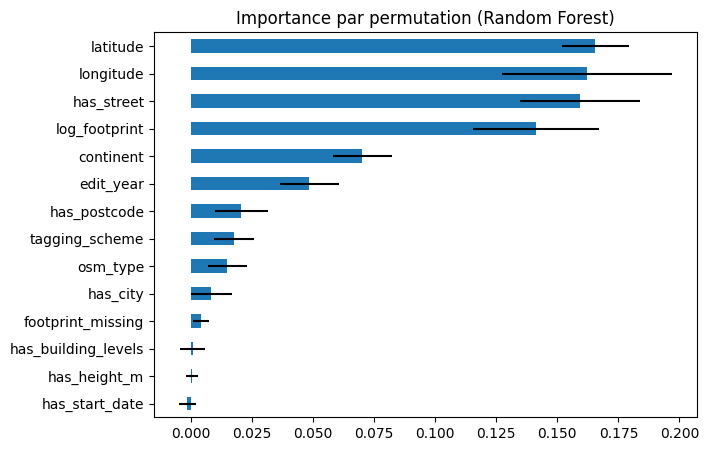

In [ ]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(best_rf, X_test, y_test, scoring='f1', n_repeats=15, random_state=42, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
print(imp.sort_values(ascending=False).round(3))
imp.plot(kind='barh', xerr=pd.Series(pi.importances_std, index=X_test.columns)[imp.index], figsize=(7,5),
         title='Importance par permutation (Random Forest)'); plt.show()

In [ ]:
# Taux d'hyperscale par continent (contexte pour l'interprétation)
print(d.groupby('continent').is_hyperscale.agg(['mean','count']).round(2).sort_values('count', ascending=False))

               mean  count
continent                 
North America  0.51    885
Europe         0.19    517
Asia           0.30     79
Oceania        0.35     51
South America  0.22     36
Africa         0.38      8


## 11. Conclusion critique *(à adapter avec VOS chiffres)*

**Modèle retenu :** le **Random Forest** (réglé). Il dépasse nettement la baseline et la régression logistique en F1 et en AUC, avec un écart-type faible en validation croisée ; les résultats sur le test sont cohérents avec la CV (pas de surapprentissage visible).

**Pourquoi pas la régression logistique ?** Plus simple et interprétable, mais la relation entre taille, localisation et type est non linéaire (interactions surface × région) : elle sous-performe.

**Ce que dit l'interprétation :** les variables les plus importantes sont la **localisation** (latitude, longitude : les hyperscale se concentrent dans certaines régions, ex. 51 % des sites étiquetés en Amérique du Nord contre 19 % en Europe), la **présence d'une adresse de rue** renseignée dans OSM, puis la **surface au sol** (les hyperscale sont en médiane ~2× plus grands que les colocations). La forte importance de `has_street` montre que le modèle exploite en partie la façon dont les contributeurs documentent les sites, pas seulement des propriétés physiques.

**Limites et biais :**
- Les étiquettes `facility_kind` ne sont pas une vérité terrain : elles sont dérivées par règles (probablement du nom/opérateur) ; on prédit donc en partie *comment OSM étiquette*, pas la réalité.
- 67 % des installations sont `unclassified` et ont été exclues : le modèle ne s'applique qu'à des sites déjà identifiables.
- Biais géographique : OSM est bien plus complet en Amérique du Nord et en Europe.
- `edit_year` et les indicateurs `has_*` reflètent le comportement des contributeurs OSM, pas les propriétés du data center.
- Les variables d'opérateur/nom ont été exclues volontairement pour éviter la fuite de données ; les inclure donnerait un score artificiellement parfait.

**Pistes :** séparation par pays/zone pour tester la généralisation géographique, classification multiclasses, ajout de `country_summary.csv` comme variables de contexte.